# 11 · What-if rescheduling (Step 8)

At 20:00 on D−1 the desk sees the day-D risk of every flight. For the **daily top 10%** (the primary policy) it tries moving the scheduled departure by whole hours on the same day and keeps a move only if the model's **predicted** number of delayed flights at that origin on D falls by at least δ, counting the effect on every other flight at that origin (congestion spill-over).

**Explicit assumptions.**

* **A1, predictive not causal.** The model's association between hour / congestion and delay is read as the effect of a move. Weather and ATC programmes are unknown at 20:00 D−1.
* **A2, scope of a move.** Same day, whole hours, block time unchanged; carrier, aircraft, route and flight number unchanged; rotations, crews and connections not modelled.
* **A3, capacity.** No origin-hour busier than that origin's busiest training hour; new hours within its observed departure hours.
* **A4, cost.** Each move costs 0.02 expected delayed flights; the window (1–2 h) and δ are chosen on **Sep–Oct** by net predicted benefit and frozen for Nov–Dec.

**Leakage.** A move edits only schedule-derived inputs and the moved flight's origin-hour history, read from a table built with the Phase 1 decision clock; tests show that scrambling every outcome from day D on leaves day D's plan unchanged (`tests/test_reschedule.py`).

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().resolve().parent
for p in (ROOT / 'src', ROOT.parent / 'phase1' / 'src'):
    sys.path.insert(0, str(p))

import aerocast_dl  # torch before XGBoost (OpenMP)
import numpy as np, pandas as pd
from IPython.display import Image, display
from aerocast_dl import config, pipeline
R, F = config.RESULTS_DIR, config.FIGURES_DIR
pd.set_option('display.precision', 4)


## 1. Rule chosen on Sep–Oct

In [2]:
sel = json.loads((R / 'selection.json').read_text())
print('model:', sel['reschedule']['model'], '| frozen rule:', sel['reschedule']['params'], '| move cost:', sel['reschedule']['move_cost'])
pd.read_csv(R / 'reschedule_tuning.csv')

model: logreg | frozen rule: {'window': 2, 'delta': 0.02} | move cost: 0.02


,window,delta,moves,moves_per_day,share_of_candidates_moved,predicted_delays_avoided,predicted_delays_avoided_per_day,avoided_per_move,net_benefit,share_moved_earlier,spillover_share
0,1,0.01,2844,46.6230,0.5089,72.8933,1.1950,0.0256,16.0133,0.5355,0.3299
1,1,0.02,1565,25.6557,0.2800,53.6496,0.8795,0.0343,22.3496,0.4754,0.3258
2,1,0.05,199,3.2623,0.0356,12.3505,0.2025,0.0621,8.3705,0.4673,0.2867
3,2,0.01,3561,58.3770,0.6371,123.7047,2.0279,0.0347,52.4847,0.5760,0.3130
4,2,0.02,2612,42.8197,0.4673,109.8039,1.8001,0.0420,57.5639,0.6045,0.3095
5,2,0.05,740,12.1311,0.1324,50.2594,0.8239,0.0679,35.4594,0.6446,0.3162


## 2. Applied to Nov–Dec, with cost sensitivity and a naive comparison

The naive rule moves every candidate one hour earlier whenever capacity allows. Comparing both shows whether the model's per-flight assessment adds anything beyond 'earlier is better'.

In [3]:
pd.read_csv(R / 'reschedule_test.csv')

,rule,cost,window,delta,moves,moves_per_day,share_of_candidates_moved,predicted_delays_avoided,predicted_delays_avoided_per_day,avoided_per_move,net_benefit,share_moved_earlier,spillover_share
0,frozen (Sep-Oct),0.00,2,0.02,2935,48.1148,0.5407,114.5857,1.8785,0.0390,114.5857,0.5394,0.2790
1,frozen (Sep-Oct),0.02,2,0.02,2935,48.1148,0.5407,114.5857,1.8785,0.0390,55.8857,0.5394,0.2790
2,frozen (Sep-Oct),0.05,2,0.02,2935,48.1148,0.5407,114.5857,1.8785,0.0390,-32.1643,0.5394,0.2790
3,naive: every candidate 1 h earlier,0.00,1,NaN,5414,88.7541,0.9974,8.3526,0.1369,0.0015,8.3526,1.0000,-3.2651
4,naive: every candidate 1 h earlier,0.02,1,NaN,5414,88.7541,0.9974,8.3526,0.1369,0.0015,-99.9274,1.0000,-3.2651
5,naive: every candidate 1 h earlier,0.05,1,NaN,5414,88.7541,0.9974,8.3526,0.1369,0.0015,-262.3474,1.0000,-3.2651


In [4]:
mv = pd.read_csv(R / 'reschedule_test_moves.csv')
print(f"{len(mv)} moves; mean risk of moved flights {mv['risk_before'].mean():.3f} -> {mv['risk_after'].mean():.3f}; spill-over share {mv['spillover'].sum() / mv['net_gain'].sum():.2f}")
mv.groupby(['origin', 'shift']).size().unstack(fill_value=0)

2935 moves; mean risk of moved flights 0.408 -> 0.380; spill-over share 0.28


shift,-2,-1,1,2
origin,,,,
EWR,400,46,89,533
JFK,253,50,64,294
LGA,785,49,33,339


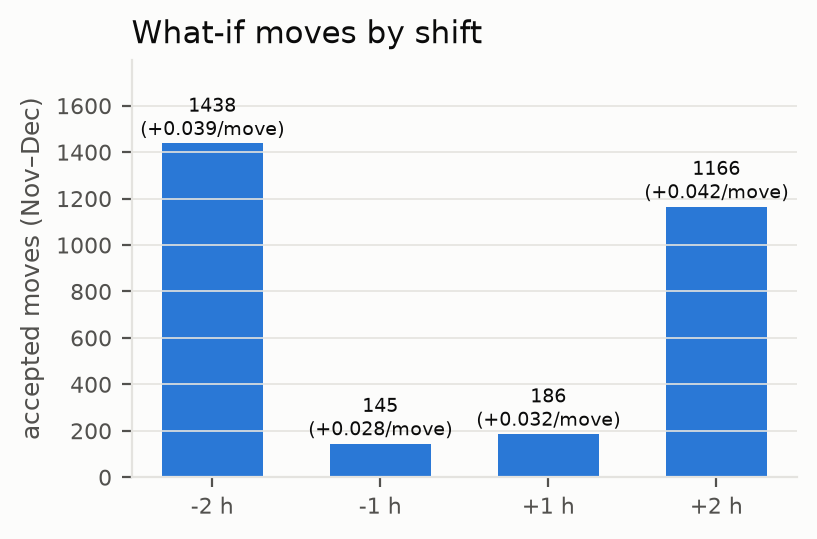

In [5]:
display(Image(F / 'reschedule_shifts.png', width=420))

## 3. How to read this

The numbers are **predicted** delays avoided under A1–A4, not realised savings: the data hold no counterfactual outcomes, no costs and no rotations. The analysis answers a narrower question: *given this model, which re-timings would a capacity-limited desk consider, and how much predicted risk would they remove?*